
- problem: bigram, not good model predictions
-  hence MLP

- By benjgio
- Through the embading space we can transfer knowledge

- 17,000(words) * 30(representation of each tensor)

- 17,000 logits(becuase 17,000 words) which is exponentialted(activated)
and normalized for output => #Softmax

- parameters are = weights and biases of output layer +  weights and biases of inner layer + embedding lookup table "C"


- 17,000 words so 30 embedding
- 27 characters so 2 embeddings to understand and we will go upto 10 embedding becomes harder to visualize 


# steps: 

build vocabulary -> x,y in build data( training, test, validation )  -> finding parameters and cleaning up the code  by  (c, w1, b1, w2, b2) ->  preparing training -> 

### Embedding:

- C starts as random number
- it will be fixed for each character like "c" will always be represented with 2 fixed embeddings [ 0.21, -0.73] and "b" will be always be represented with may be [ 1.15,  0.42]
- assigning a vector containing 2 numbers for each character is a hyperparameter
- we assign a vector containing 2 numbers because it helps to learn relationship between different characters like 'ac' or 'ad' or 'af' or 'am' which is difficult for one number to represent all this type of conditions.  


#### where does shape C[x] = [32, 3, 2] 
- X.shape = [32, 3]

- Xtr[ix] = [3, 1]

- C.shape = [27, 2]

- one lookup:
- C[some_number] → [2]

- Therefore: C[X] → [32, 3, 2] 
- 32 and 3 come from X; 2 comes from each selected row of C
- "For every number inside X, go to that row of C and give me the 2 numbers stored there."

- [32, 3, 2] here this shape because 32 examples, 3 charachers for each example and 2 numbers representing each character

- Example below of [32, 3, 2] shape. 

## cross_entropy for efficiency:


- logits = h @ W2 + b2 
- ======

- counts = logits.exp()
- prob = counts / counts. sum(1, keepdims=True)
- loss = -prob[torch. arange(32), Y].log().mean()

- (or ) 

- F. cross_entropy (logits, Y)

# Finding a Good Initial Learning Rate

1. find learning rates from very low to very high and watch how loss behaves.
2. **High LR** → loss unstable, bounces up/down (overshoots); can diverge.
3. **Low LR** → loss decreases, but slowly and smoothly — safe, just inefficient.
4. Sweep exponentially (LRs span orders of magnitude, so linear spacing wastes steps):
   ```python
   lre = torch.linspace(-3, 0, 1000)   # learning rate exponents
   lrs = 10**lre                       # actual learning rates
   ```
5. `lre` = exponents, `lrs` = actual rates, "wrt" = "with respect to."
6. In the loop, use one LR per step and track both:
   ```python
   lr = lrs[i]
   for p in parameters:
       p.data += -lr * p.grad

   lri.append(lre[i])
   lossi.append(loss.item())
   ```
7. Plot: `plt.plot(lri, lossi)`
8. we get the J shape which will help to determine the learning rate 

# MiniBatches

1. why less loss doesn't mean that it's a good model => as more the number of parameters and neurons model starts to overfitting or verbatim( exactly as it was spoken or written )


In [ ]:
# [32, 3, 2] shape 


# [
#   [ [0.2, 0.5], [0.7, 0.1], [-0.3, 0.8] ],   ← example 0
#   [ [0.4, 0.2], [0.1, 0.9], [0.6, 0.3] ],    ← example 1
#   [ [0.8, 0.1], [0.2, 0.4], [0.5, 0.7] ],    ← example 2
#   ...
#   [ [...], [...], [...] ]                     ← example 31
# ]

In [ ]:
import torch 
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8] 

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [ ]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [ ]:

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
... ---> a
..a ---> v
.av ---> a
ava ---> .
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .


In [ ]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [ ]:
C = torch.randn((27, 2))

In [ ]:
emb = C[X]
emb.shape


torch.Size([32, 3, 2])

In [ ]:
x = torch.tensor([
        [ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]
        ])

- loss = F.cross_entropy(logits, Ytr[ix]) 
- |||||
- counts = logits.exp()
- prob = counts / counts. sum (1, keepdims=True)
- loss = -prob[torch.arange(32), Y]. log() mean()


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt 
%matplotlib inline


In [ ]:

words = open("names.txt", 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [ ]:
len(words)

32033

In [ ]:
#build the vocabulary of chharacters and mapping to/from integers
chars= sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [ ]:
# build the dataset
block_size = 3
X, Y = [], []
for w in words:
   
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        
        context = context[1:] + [ix] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

In [ ]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [ ]:
# for bigger set

block_size = 3

def build_dataset(words):
    X, Y = [], []
    for w in words:

        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))


Xtr, Ytr = build_dataset(words[:n1]) # training set
Xdev, Ydev = build_dataset(words[n1:n2]) # dev set 
Xte, Yte = build_dataset(words[n2:]) # validation set




torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [ ]:
C = torch.randn((27, 2))

In [ ]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [ ]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [ ]:
# pytorch operation => randint syntax
#torch.randint(low=0, high, size, *, generator=None, dtype=torch.int64, layout=torch.strided, device=None, requires_grad=False)


In [ ]:
random_numbers = torch.rand(30, 3)
print(f"random numbers shape: ",random_numbers.shape)
print(f"number of rows but called using shape: ",random_numbers.shape[0])
print(f'number of columns but called using shape: ',random_numbers.shape[1])

random numbers shape:  torch.Size([30, 3])
number of rows but called using shape:  30
number of columns but called using shape:  3


In [ ]:

random_numbers

tensor([[0.6032, 0.5174, 0.8328],
        [0.2195, 0.3998, 0.9836],
        [0.7881, 0.8462, 0.3726],
        [0.3386, 0.2673, 0.0558],
        [0.0218, 0.1754, 0.1248],
        [0.2514, 0.8299, 0.3261],
        [0.4344, 0.2382, 0.8050],
        [0.2283, 0.4293, 0.8528],
        [0.3038, 0.3060, 0.3170],
        [0.4998, 0.1677, 0.3742],
        [0.7254, 0.3815, 0.0868],
        [0.3079, 0.8882, 0.6733],
        [0.8026, 0.5175, 0.7034],
        [0.1612, 0.1898, 0.3934],
        [0.0056, 0.7539, 0.5756],
        [0.7939, 0.3857, 0.4036],
        [0.7690, 0.3067, 0.9501],
        [0.8570, 0.7737, 0.1309],
        [0.5888, 0.7851, 0.7534],
        [0.9487, 0.5054, 0.2800],
        [0.0644, 0.9930, 0.1473],
        [0.0789, 0.4832, 0.3736],
        [0.4663, 0.9216, 0.3541],
        [0.3563, 0.0973, 0.7749],
        [0.1924, 0.2750, 0.1385],
        [0.8618, 0.2020, 0.2535],
        [0.4051, 0.2919, 0.5359],
        [0.2478, 0.1471, 0.3927],
        [0.4901, 0.6590, 0.9531],
        [0.527

In [ ]:
ix = torch.randint(0, random_numbers.shape[0], (3, )) # here 3 means 3 rows 

print(ix.shape)
print("One number in the tuple = one dimension in the output. (32,) says \n"
      "make a tensor with 1 dimension, and that dimension has 3 slots \n\n"
      "— i.e., a flat list of 3 numbers, like a single row: ", random_numbers[ix], "\n")


print("====================\n")

ix = torch.randint(0, random_numbers.shape[0], (3, 2)) # here 3 means 3 rows and 2 is columns 

print(ix.shape)
print("Two numbers in the tuple = two dimensions. (3, 4) says \n"
      "make a tensor with 2 dimensions: the first has 3 slots, the second has 4 slots \n\n"
      "— i.e., a grid with 3 rows and 4 columns, 3 x 4 = 12 numbers total: ", random_numbers[ix])

torch.Size([3])
One number in the tuple = one dimension in the output. (32,) says 
make a tensor with 1 dimension, and that dimension has 3 slots 

— i.e., a flat list of 3 numbers, like a single row:  tensor([[0.0056, 0.7539, 0.5756],
        [0.0056, 0.7539, 0.5756],
        [0.2514, 0.8299, 0.3261]]) 


torch.Size([3, 2])
Two numbers in the tuple = two dimensions. (3, 4) says 
make a tensor with 2 dimensions: the first has 3 slots, the second has 4 slots 

— i.e., a grid with 3 rows and 4 columns, 3 x 4 = 12 numbers total:  tensor([[[0.5888, 0.7851, 0.7534],
         [0.6032, 0.5174, 0.8328]],

        [[0.3563, 0.0973, 0.7749],
         [0.8026, 0.5175, 0.7034]],

        [[0.2514, 0.8299, 0.3261],
         [0.7939, 0.3857, 0.4036]]])


- ix = 32  where 32 is 32 random row numbers 
- xtr = 2 lakh, 3 
- c = 27, 10

one min batch:
32, 3, 10 by emb = C[Xtr[ix]]
- ix gives 32 random numbers 
- Xtr[ix] will give 32, 3 where 32 is the number of examples and 3 is the the representation of each character
- C shape is 27, 10 
- when we do C[Xtr[ix]] 
- out of the chosen 32 random number passed into Xtr 
- each value of Xtr will give 3 * 10 tensor where 3 is the number of characters and 10 is the representation of each letter
- C[Xtr[ix]] is of size 32, 3, 10 so, we get out where 32 is the random numbers 

In [ ]:
g = torch.Generator().manual_seed(2233)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [ ]:
sum(p.nelement() for p in parameters)

11897

In [ ]:
for p in parameters:
    p.requires_grad = True

In [ ]:
lre = torch.linspace(-3, 0,  1000)
lrs = 10**lre

In [ ]:
lri = []
lossi = []
stepi = []

In [ ]:
for i in range(200000):

    # minibatch construct 
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # 32, 3, 10
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    for p in parameters:
        p.grad = None
    loss.backward()

    # update 
    # lr = lrs[i]
    lr = 0.1 if i < 1000000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    stepi.append(i)
    lossi.append(loss.log10().item())

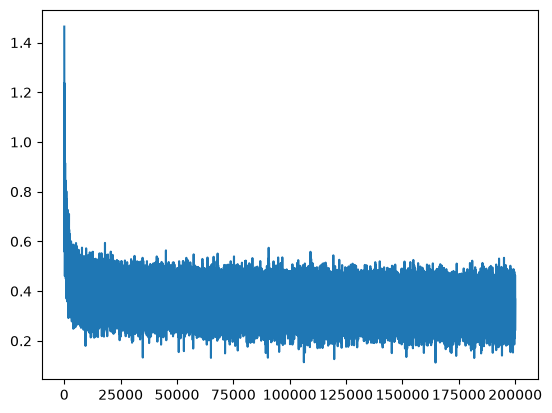

In [ ]:
plt.plot(stepi, lossi)

In [ ]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss


tensor(2.2787, grad_fn=<NllLossBackward0>)

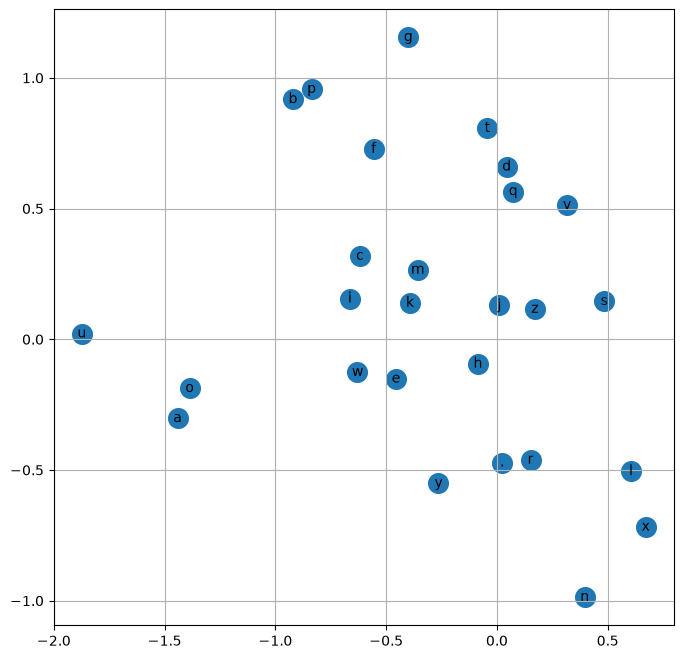

In [ ]:
plt.figure(figsize=(8,8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i, 1].item(), itos[i], ha = "center", va="center", color="black")
plt.grid('minor')

In [ ]:
content = [0] * block_size
C[torch.tensor([content])].shape

torch.Size([1, 3, 10])

In [ ]:

# sample from the model 
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(30):

    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits= h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

carmahzavi.
harli.
jmriegentlennandene.
rahnen.
deviah.
avreni.
ner.
kra.
chriivon.
levyn.
ham.
frin.
quinn.
sulinevina.
brio.
arron.
jarynn.
fraegrifsan.
evaedo.
abgina.
jasri.
alaan.
bra.
husya.
ambrosozelynnen.
aria.
roenek.
kaadhieonnon.
sriona.
krynn.


In [ ]:
ix.shape, Xtr.shape, Xb.shape,
emb.shape,
embcat.shape, 



(torch.Size([32]),
 torch.Size([182625, 3]),
 torch.Size([32, 3]),
 torch.Size([182625, 3, 10]),
 torch.Size([182625, 30]),
 hpreact.shape,
 torch.Size([182625, 200]),
 bnmeani.shape,
 torch.Size([1, 200]),
 bnstdi.shape,
 torch.Size([1, 200]),
hpreact.shape
 torch.Size([182625, 200]))

bngain = ones 
bnbias = zeros
bnmean_running = zeros
bnstd_running = ones 